# Neural Network 2L

In [233]:
%pip install torch


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: /Users/godiva/Desktop/UGA/2nd Year/Spring Semester/VIPR/Project/CoolDawgs_PersonalizationGrp/CoolDawgs/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [234]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error
import copy

In [235]:
print("PyTorch Version:", torch.__version__)
print("PyTorch Installed Successfully!")

PyTorch Version: 2.13.0
PyTorch Installed Successfully!


## Data Loading and Preprocessing

In [236]:
# airfoil
airfoil = pd.read_csv("../data/airfoil.csv")
print("\n**************** AIRFOIL DATASET ✈️ ****************")
print(airfoil.head())
print("\nShape:", airfoil.shape)
print("\nColumns:", airfoil.columns.tolist())

# auto mpg
auto = pd.read_csv("../data/auto_mpg.csv")
print("\n**************** AUTO MPG DATASET 🚗 ****************")
print(auto.head())
print("\nShape:", auto.shape)
print("\nColumns:", auto.columns.tolist())

# concrete
concrete = pd.read_csv("../data/concrete.csv")
print("\n**************** CONCRETE DATASET 🛣️ ****************")
print(concrete.head())
print("\nShape:", concrete.shape)
print("\nColumns:", concrete.columns.tolist())


**************** AIRFOIL DATASET ✈️ ****************
   frequency_hz  angle_attack_deg  chord_length_m  free_stream_velocity_ms  \
0           800               0.0          0.3048                     71.3   
1          1000               0.0          0.3048                     71.3   
2          1250               0.0          0.3048                     71.3   
3          1600               0.0          0.3048                     71.3   
4          2000               0.0          0.3048                     71.3   

   suction_displacement_thickness_m  scaled_sound_pressure_db  
0                          0.002663                   126.201  
1                          0.002663                   125.201  
2                          0.002663                   125.951  
3                          0.002663                   127.591  
4                          0.002663                   127.461  

Shape: (1503, 6)

Columns: ['frequency_hz', 'angle_attack_deg', 'chord_length_m', 'free_stre

In [237]:
# check for missing values
datasets = {
    "Airfoil": airfoil,
    "Auto MPG": auto,
    "Concrete": concrete
}

for name, df in datasets.items():
    if df.isnull().sum().sum() > 0:
        print(f"{name}: Missing values found ❌")
    else:
        print(f"{name}: No missing values ✅")

Airfoil: No missing values ✅
Auto MPG: No missing values ✅
Concrete: No missing values ✅


In [238]:
# separate predictors and target

# airfoil
X_airfoil = airfoil.drop(columns=["scaled_sound_pressure_db"])
y_airfoil = airfoil["scaled_sound_pressure_db"]
print("\n**************** AIRFOIL TARGET VARIABLE ✈️ ****************")
print(y_airfoil.head())

# auto mpg
X_auto = auto.drop(columns=["mpg"])
y_auto = auto["mpg"]
print("\n**************** AUTO MPG TARGET VARIABLE 🚗 ****************")
print(y_auto.head())

# concrete
X_concrete = concrete.drop(columns=["compressive_strength_mpa"])
y_concrete = concrete["compressive_strength_mpa"]
print("\n**************** CONCRETE TARGET VARIABLE 🛣️ ****************")
print(y_concrete.head())


**************** AIRFOIL TARGET VARIABLE ✈️ ****************
0    126.201
1    125.201
2    125.951
3    127.591
4    127.461
Name: scaled_sound_pressure_db, dtype: float64

**************** AUTO MPG TARGET VARIABLE 🚗 ****************
0    18.0
1    15.0
2    18.0
3    16.0
4    17.0
Name: mpg, dtype: float64

**************** CONCRETE TARGET VARIABLE 🛣️ ****************
0    79.986111
1    61.887366
2    40.269535
3    41.052780
4    44.296075
Name: compressive_strength_mpa, dtype: float64


In [239]:
# split data into 80% training and 20% testing

# airfoil
X_airfoil_train, X_airfoil_test, y_airfoil_train, y_airfoil_test = train_test_split(
    X_airfoil,
    y_airfoil,
    test_size=0.20,
    random_state=42
)

# auto mpg
X_auto_train, X_auto_test, y_auto_train, y_auto_test = train_test_split(
    X_auto,
    y_auto,
    test_size=0.20,
    random_state=42
)

# concrete
X_concrete_train, X_concrete_test, y_concrete_train, y_concrete_test = train_test_split(
    X_concrete,
    y_concrete,
    test_size=0.20,
    random_state=42
)

# verify splits
print("Airfoil:", X_airfoil_train.shape, X_airfoil_test.shape)
print("Auto MPG:", X_auto_train.shape, X_auto_test.shape)
print("Concrete:", X_concrete_train.shape, X_concrete_test.shape)

Airfoil: (1202, 5) (301, 5)
Auto MPG: (313, 7) (79, 7)
Concrete: (824, 8) (206, 8)


## Neural Network Setup

In [240]:
# standardize predictors

# airfoil
scaler_airfoil = StandardScaler()
X_airfoil_train = scaler_airfoil.fit_transform(X_airfoil_train)
X_airfoil_test = scaler_airfoil.transform(X_airfoil_test)

# auto mpg
scaler_auto = StandardScaler()
X_auto_train = scaler_auto.fit_transform(X_auto_train)
X_auto_test = scaler_auto.transform(X_auto_test)


# concrete
scaler_concrete = StandardScaler()
X_concrete_train = scaler_concrete.fit_transform(X_concrete_train)
X_concrete_test = scaler_concrete.transform(X_concrete_test)

# verify standardization
print("Airfoil standardized:", X_airfoil_train.mean().round(2))
print("Auto MPG standardized:", X_auto_train.mean().round(2))
print("Concrete standardized:", X_concrete_train.mean().round(2))

Airfoil standardized: 0.0
Auto MPG standardized: -0.0
Concrete standardized: 0.0


In [241]:
# convert predictors and targets into pytorch tensors

# airfoil
X_airfoil_train = torch.tensor(X_airfoil_train, dtype=torch.float32) # float32 ensures compatibility with pytorch neural nets weights
X_airfoil_test = torch.tensor(X_airfoil_test, dtype=torch.float32)
y_airfoil_train = torch.tensor(y_airfoil_train.to_numpy(), dtype=torch.float32).reshape(-1, 1) #reshape makes targets a single col to match model preds
y_airfoil_test = torch.tensor(y_airfoil_test.to_numpy(), dtype=torch.float32).reshape(-1, 1)

# auto mpg
X_auto_train = torch.tensor(X_auto_train, dtype=torch.float32) 
X_auto_test = torch.tensor(X_auto_test, dtype=torch.float32)
y_auto_train = torch.tensor(y_auto_train.to_numpy(), dtype=torch.float32).reshape(-1, 1) 
y_auto_test = torch.tensor(y_auto_test.to_numpy(), dtype=torch.float32).reshape(-1, 1)

# concrete
X_concrete_train = torch.tensor(X_concrete_train, dtype=torch.float32) 
X_concrete_test = torch.tensor(X_concrete_test, dtype=torch.float32)
y_concrete_train = torch.tensor(y_concrete_train.to_numpy(), dtype=torch.float32).reshape(-1, 1) 
y_concrete_test = torch.tensor(y_concrete_test.to_numpy(), dtype=torch.float32).reshape(-1, 1)

# verify tensor conversion
print("Airfoil Tensors:", X_airfoil_train.shape, y_airfoil_train.shape)
print("Auto MPG Tensors:", X_auto_train.shape, y_auto_train.shape)
print("Concrete Tensors:", X_concrete_train.shape, y_concrete_train.shape)

Airfoil Tensors: torch.Size([1202, 5]) torch.Size([1202, 1])
Auto MPG Tensors: torch.Size([313, 7]) torch.Size([313, 1])
Concrete Tensors: torch.Size([824, 8]) torch.Size([824, 1])


In [242]:
# define 2-layer neural network
class NeuralNet2L(nn.Module):
    def __init__(self, input_size): # input size is num of input features
        super().__init__()
        self.linear = nn.Linear(input_size, 1) # creates fully connected layer that learns weights and bias

    def forward(self, x):
        return self.linear(x) # sends inputs through the lin layer and returns pred val

In [243]:
# create 2L models for each dataset

model_airfoil = NeuralNet2L(X_airfoil_train.shape[1])
model_auto = NeuralNet2L(X_auto_train.shape[1])
model_concrete = NeuralNet2L(X_concrete_train.shape[1])

print(model_airfoil)
print(model_auto)
print(model_concrete)

NeuralNet2L(
  (linear): Linear(in_features=5, out_features=1, bias=True)
)
NeuralNet2L(
  (linear): Linear(in_features=7, out_features=1, bias=True)
)
NeuralNet2L(
  (linear): Linear(in_features=8, out_features=1, bias=True)
)


## Hyperparameter Tuning

In [244]:
# tune hyperparameters using validation mse and early stopping
def hyperparameter_tuning(X, y):
    
    # split training data for hyperparameter tuning
    X_train, X_val, y_train, y_val = train_test_split(
        X, y, test_size=0.20, random_state=42
    )

    # standardize predictors using only training data
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_val = scaler.transform(X_val)

    # convert predictors and targets into pytorch tensors
    X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.float32).reshape(-1, 1)
    X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
    y_val_tensor = torch.tensor(y_val.to_numpy(), dtype=torch.float32).reshape(-1, 1)

    # define hyperparameter values and early stopping settings
    learning_rates = [0.001, 0.01, 0.05, 0.1, 0.15, 0.2, 0.3]
    batch_sizes = [16, 32, 64]
    max_epochs = 100
    patience = 10

    # store best hyperparameters and loss history
    results = []
    best_history = None
    best_params = None
    best_mse = float("inf")

    # test all combinations of learning rates and batch sizes
    for lr in learning_rates:
        for batch_size in batch_sizes:

            print(f"Testing LR={lr}, Batch={batch_size}", flush=True)

            # create 2L neural network
            torch.manual_seed(42)
            model = NeuralNet2L(X_train_tensor.shape[1])

            # define loss function and adam optimizer
            criterion = nn.MSELoss()
            optimizer = optim.Adam(model.parameters(), lr=lr)

            # create mini-batches
            loader = DataLoader(
                TensorDataset(X_train_tensor, y_train_tensor),
                batch_size=batch_size,
                shuffle=True
            )

            # track losses and early stopping
            train_losses = []
            val_losses = []
            best_val_mse = float("inf")
            best_epoch = 0
            wait = 0

            # train neural network for max of 100 epochs
            for epoch in range(max_epochs):
                model.train()

                # predict, calculate loss, and update weights
                for X_batch, y_batch in loader:
                    optimizer.zero_grad()
                    predictions = model(X_batch)
                    loss = criterion(predictions, y_batch)
                    loss.backward()
                    optimizer.step()

                # calculate training and validation mse
                model.eval()
                torch.set_grad_enabled(False)
                train_mse = criterion(model(X_train_tensor), y_train_tensor).item()
                val_mse = criterion(model(X_val_tensor), y_val_tensor).item()
                torch.set_grad_enabled(True)

                # store losses for plotting
                train_losses.append(train_mse)
                val_losses.append(val_mse)

                # check whether validation loss improved
                if val_mse < best_val_mse:
                    best_val_mse = val_mse
                    best_epoch = epoch + 1
                    wait = 0
                else:
                    wait += 1

                # stop if validation loss does not improve
                if wait >= patience:
                    print(f"Early stopping at epoch {epoch + 1}")
                    break

            # save results for current hyperparameters
            results.append({
                "learning_rate": lr,
                "batch_size": batch_size,
                "val_mse": best_val_mse,
                "epochs": len(train_losses),
                "best_epoch": best_epoch
            })

            print(
                f"LR={lr}, Batch={batch_size}, "
                f"Validation MSE={best_val_mse:.4f}"
            )

            # save best hyperparameters and loss curves
            if best_val_mse < best_mse:
                best_mse = best_val_mse
                best_params = results[-1]
                best_history = {
                    "train": train_losses,
                    "val": val_losses
                }

    print("\nBest Hyperparameters:", best_params)
    return best_params, results, best_history

In [246]:
# hyperparameter tuning for airfoil dataset
print("Tuning Airfoil...")
X_airfoil_tune, _, y_airfoil_tune, _ = train_test_split(X_airfoil, y_airfoil, test_size=0.20, random_state=42)
best_airfoil, results_airfoil, history_airfoil = hyperparameter_tuning(X_airfoil_tune, y_airfoil_tune)

Tuning Airfoil...
Testing LR=0.001, Batch=16
LR=0.001, Batch=16, Validation MSE=14316.6201
Testing LR=0.001, Batch=32
LR=0.001, Batch=32, Validation MSE=15041.3857
Testing LR=0.001, Batch=64
LR=0.001, Batch=64, Validation MSE=15412.2891
Testing LR=0.01, Batch=16
LR=0.01, Batch=16, Validation MSE=4756.5215
Testing LR=0.01, Batch=32
LR=0.01, Batch=32, Validation MSE=9215.0029
Testing LR=0.01, Batch=64
LR=0.01, Batch=64, Validation MSE=12116.5996
Testing LR=0.05, Batch=16
LR=0.05, Batch=16, Validation MSE=32.1095
Testing LR=0.05, Batch=32
LR=0.05, Batch=32, Validation MSE=326.7408
Testing LR=0.05, Batch=64
LR=0.05, Batch=64, Validation MSE=3328.6655
Testing LR=0.1, Batch=16
Early stopping at epoch 68
LR=0.1, Batch=16, Validation MSE=31.7743
Testing LR=0.1, Batch=32
LR=0.1, Batch=32, Validation MSE=32.5641
Testing LR=0.1, Batch=64
LR=0.1, Batch=64, Validation MSE=372.9065
Testing LR=0.15, Batch=16
Early stopping at epoch 55
LR=0.15, Batch=16, Validation MSE=31.9117
Testing LR=0.15, Batch=3

In [247]:
# hyperparameter tuning for auto mpg dataset
print("\nTuning Auto MPG...")
X_auto_tune, _, y_auto_tune, _ = train_test_split(X_auto, y_auto, test_size=0.20, random_state=42) 
best_auto, results_auto, history_auto = hyperparameter_tuning(X_auto_tune, y_auto_tune)


Tuning Auto MPG...
Testing LR=0.001, Batch=16
LR=0.001, Batch=16, Validation MSE=479.4442
Testing LR=0.001, Batch=32
LR=0.001, Batch=32, Validation MSE=520.8967
Testing LR=0.001, Batch=64
LR=0.001, Batch=64, Validation MSE=547.9635
Testing LR=0.01, Batch=16
LR=0.01, Batch=16, Validation MSE=107.0358
Testing LR=0.01, Batch=32
LR=0.01, Batch=32, Validation MSE=262.2959
Testing LR=0.01, Batch=64
LR=0.01, Batch=64, Validation MSE=385.0519
Testing LR=0.05, Batch=16
Early stopping at epoch 97
LR=0.05, Batch=16, Validation MSE=7.8135
Testing LR=0.05, Batch=32
LR=0.05, Batch=32, Validation MSE=9.5504
Testing LR=0.05, Batch=64
LR=0.05, Batch=64, Validation MSE=67.0796
Testing LR=0.1, Batch=16
Early stopping at epoch 59
LR=0.1, Batch=16, Validation MSE=7.8256
Testing LR=0.1, Batch=32
Early stopping at epoch 83
LR=0.1, Batch=32, Validation MSE=7.8102
Testing LR=0.1, Batch=64
LR=0.1, Batch=64, Validation MSE=9.3353
Testing LR=0.15, Batch=16
Early stopping at epoch 42
LR=0.15, Batch=16, Validation

In [248]:
# hyperparameter tuning for concrete dataset
print("\nTuning Concrete...")
X_concrete_tune, _, y_concrete_tune, _ = train_test_split(X_concrete, y_concrete, test_size=0.20, random_state=42) 
best_concrete, results_concrete, history_concrete = hyperparameter_tuning(X_concrete_tune, y_concrete_tune)


Tuning Concrete...
Testing LR=0.001, Batch=16
LR=0.001, Batch=16, Validation MSE=1081.7654
Testing LR=0.001, Batch=32
LR=0.001, Batch=32, Validation MSE=1236.8318
Testing LR=0.001, Batch=64
LR=0.001, Batch=64, Validation MSE=1326.1278
Testing LR=0.01, Batch=16
LR=0.01, Batch=16, Validation MSE=127.0381
Testing LR=0.01, Batch=32
LR=0.01, Batch=32, Validation MSE=367.5201
Testing LR=0.01, Batch=64
LR=0.01, Batch=64, Validation MSE=685.6497
Testing LR=0.05, Batch=16
Early stopping at epoch 46
LR=0.05, Batch=16, Validation MSE=112.6712
Testing LR=0.05, Batch=32
Early stopping at epoch 76
LR=0.05, Batch=32, Validation MSE=110.9197
Testing LR=0.05, Batch=64
LR=0.05, Batch=64, Validation MSE=113.4704
Testing LR=0.1, Batch=16
Early stopping at epoch 62
LR=0.1, Batch=16, Validation MSE=108.2277
Testing LR=0.1, Batch=32
Early stopping at epoch 42
LR=0.1, Batch=32, Validation MSE=110.5730
Testing LR=0.1, Batch=64
Early stopping at epoch 76
LR=0.1, Batch=64, Validation MSE=109.9590
Testing LR=0.1

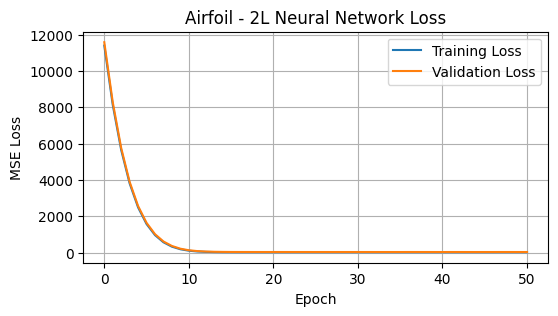

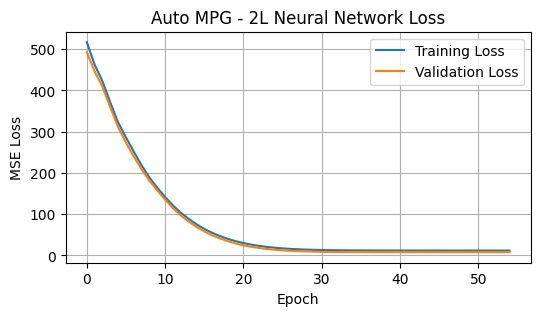

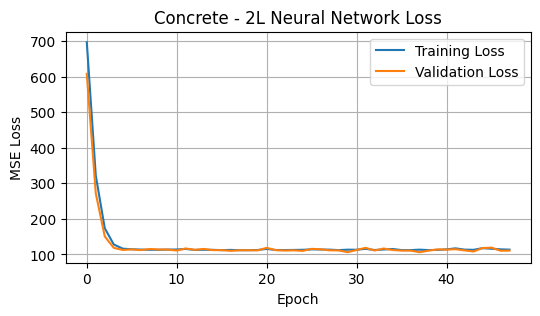

In [249]:
# plot training and validation loss curves
def plot_loss(history, dataset_name):
    plt.figure(figsize=(6, 3))

    # create plot
    plt.plot(history["train"], label="Training Loss")
    plt.plot(history["val"], label="Validation Loss")

    # plot details
    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")
    plt.title(f"{dataset_name} - 2L Neural Network Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_loss(history_airfoil, "Airfoil")
plot_loss(history_auto, "Auto MPG")
plot_loss(history_concrete, "Concrete")

## Model Training

In [250]:
# train final 2L neural network using best hyperparameters
def train_final_model(X_train, y_train, best_params):
    # create 2L neural network
    torch.manual_seed(42)
    model = NeuralNet2L(X_train.shape[1])

    # define loss function and optimizer
    criterion = nn.MSELoss()
    optimizer = optim.Adam(
        model.parameters(),
        lr=best_params["learning_rate"]
    )

    # create mini-batches
    loader = DataLoader(
        TensorDataset(X_train, y_train),
        batch_size=best_params["batch_size"],
        shuffle=True
    )

    # train using the best hyperparameters
    model.train()
    for epoch in range(best_params["best_epoch"]):
        for X_batch, y_batch in loader:
            optimizer.zero_grad()
            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)
            loss.backward()
            optimizer.step()

    return model

In [251]:
# train final airfoil model
model_airfoil = train_final_model(
    X_airfoil_train,
    y_airfoil_train,
    best_airfoil
)

print("Airfoil:", model_airfoil)

Airfoil: NeuralNet2L(
  (linear): Linear(in_features=5, out_features=1, bias=True)
)


In [252]:
# train final auto mpg model
model_auto = train_final_model(
    X_auto_train,
    y_auto_train,
    best_auto
)

print("Auto MPG:", model_auto)

Auto MPG: NeuralNet2L(
  (linear): Linear(in_features=7, out_features=1, bias=True)
)


In [253]:
# train final concrete model
model_concrete = train_final_model(
    X_concrete_train,
    y_concrete_train,
    best_concrete
)

print("Concrete:", model_concrete)

Concrete: NeuralNet2L(
  (linear): Linear(in_features=8, out_features=1, bias=True)
)


## Model Evaluation (QoF)

In [254]:
# calculate r², mse, and rmse for neural network predictions
def evaluate_model(model, X, y):
    model.eval()

    # generate predictions without tracking gradients
    torch.set_grad_enabled(False)
    predictions = model(X).numpy()
    torch.set_grad_enabled(True)

    actual = y.numpy()

    # calculate quality of fit
    r2 = r2_score(actual, predictions)
    mse = mean_squared_error(actual, predictions)
    rmse = np.sqrt(mse)

    return r2, mse, rmse

In [255]:
# calculate in-sample and validation QoF for airfoil dataset

# calculate in-sample (training) QoF
train_r2, train_mse, train_rmse = evaluate_model(
    model_airfoil, X_airfoil_train, y_airfoil_train
)

# calculate out-of-sample (validation) QoF
val_r2, val_mse, val_rmse = evaluate_model(
    model_airfoil, X_airfoil_test, y_airfoil_test
)

print("Airfoil QoF")
print(f"Training: R²={train_r2:.4f}, MSE={train_mse:.4f}, RMSE={train_rmse:.4f}")
print(f"Validation: R²={val_r2:.4f}, MSE={val_mse:.4f}, RMSE={val_rmse:.4f}")

Airfoil QoF
Training: R²=0.4977, MSE=23.5637, RMSE=4.8542
Validation: R²=0.5528, MSE=22.4060, RMSE=4.7335


In [256]:
# calculate in-sample and validation QoF for auto mpg dataset

# calculate in-sample (training) QoF
train_r2, train_mse, train_rmse = evaluate_model(
    model_auto, X_auto_train, y_auto_train
)

# calculate out-of-sample (validation) QoF
val_r2, val_mse, val_rmse = evaluate_model(
    model_auto, X_auto_test, y_auto_test
)

print("Auto MPG QoF")
print(f"Training: R²={train_r2:.4f}, MSE={train_mse:.4f}, RMSE={train_rmse:.4f}")
print(f"Validation: R²={val_r2:.4f}, MSE={val_mse:.4f}, RMSE={val_rmse:.4f}")

Auto MPG QoF
Training: R²=0.8255, MSE=11.0082, RMSE=3.3179
Validation: R²=0.7829, MSE=11.0810, RMSE=3.3288


In [257]:
# calculate in-sample and validation QoF for concrete dataset

# calculate in-sample (training) QoF
train_r2, train_mse, train_rmse = evaluate_model(
    model_concrete, X_concrete_train, y_concrete_train
)

# calculate out-of-sample (validation) QoF
val_r2, val_mse, val_rmse = evaluate_model(
    model_concrete, X_concrete_test, y_concrete_test
)

print("Concrete QoF")
print(f"Training: R²={train_r2:.4f}, MSE={train_mse:.4f}, RMSE={train_rmse:.4f}")
print(f"Validation: R²={val_r2:.4f}, MSE={val_mse:.4f}, RMSE={val_rmse:.4f}")

Concrete QoF
Training: R²=0.6053, MSE=112.1226, RMSE=10.5888
Validation: R²=0.6236, MSE=96.9818, RMSE=9.8479


In [270]:
# compare QoF results across all three datasets

qof_results = []

datasets = {
    "Airfoil": (model_airfoil, X_airfoil_train, y_airfoil_train,
                X_airfoil_test, y_airfoil_test),

    "Auto MPG": (model_auto, X_auto_train, y_auto_train,
                 X_auto_test, y_auto_test),

    "Concrete": (model_concrete, X_concrete_train, y_concrete_train,
                 X_concrete_test, y_concrete_test)
}

# calculate training and validation QoF for each dataset
for name, (model, X_train, y_train, X_val, y_val) in datasets.items():
    train_r2, train_mse, train_rmse = evaluate_model(model, X_train, y_train)
    val_r2, val_mse, val_rmse = evaluate_model(model, X_val, y_val)

    qof_results.append({
        "Dataset": name,
        "Train R²": train_r2,
        "Validation R²": val_r2,
        "Train MSE": train_mse,
        "Validation MSE": val_mse,
        "Train RMSE": train_rmse,
        "Validation RMSE": val_rmse
    })

# convert QoF results into a dataframe
qof_df = pd.DataFrame(qof_results)

# display QoF comparison table
print("\n2L Neural Network - Quality of Fit")
print(qof_df.round(4).to_string(index=False))


2L Neural Network - Quality of Fit
 Dataset  Train R²  Validation R²  Train MSE  Validation MSE  Train RMSE  Validation RMSE
 Airfoil    0.4977         0.5528    23.5637         22.4060      4.8542           4.7335
Auto MPG    0.8255         0.7829    11.0082         11.0810      3.3179           3.3288
Concrete    0.6053         0.6236   112.1226         96.9818     10.5888           9.8479


## Visualizations 

In [271]:
# plot actual vs. predicted values
def plot_predictions(model, X, y, dataset_name, split_name):
    model.eval()

    # generate predictions and get actual values
    torch.set_grad_enabled(False)
    predictions = model(X).numpy().flatten()
    torch.set_grad_enabled(True)
    actual = y.numpy().flatten()

    # create scatter plot
    plt.figure(figsize=(7, 5))
    plt.scatter(actual, predictions, alpha=0.5)

    # plot perfect prediction line
    min_val = min(actual.min(), predictions.min())
    max_val = max(actual.max(), predictions.max())
    plt.plot([min_val, max_val], [min_val, max_val], "r--")

    # plot details
    plt.xlabel("Actual Values")
    plt.ylabel("Predicted Values")
    plt.title(f"{dataset_name} - 2L {split_name}")
    plt.grid(True)
    plt.show()

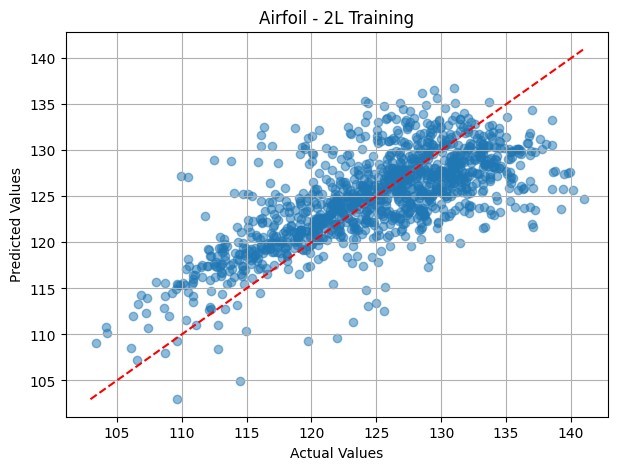

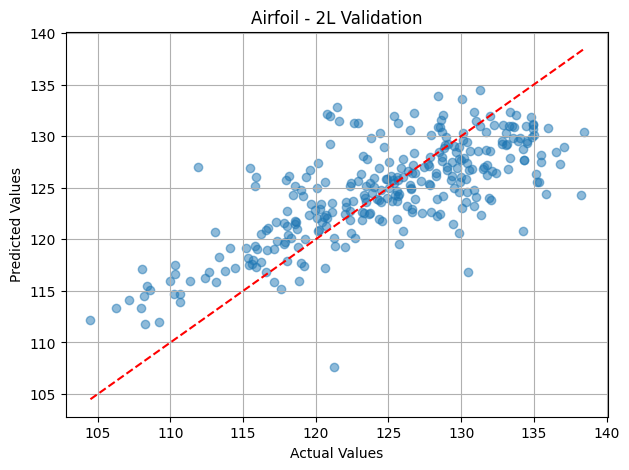

In [272]:
# airfoil in-sample and validation plots
plot_predictions(model_airfoil, X_airfoil_train, y_airfoil_train, "Airfoil", "Training")
plot_predictions(model_airfoil, X_airfoil_test, y_airfoil_test, "Airfoil", "Validation")

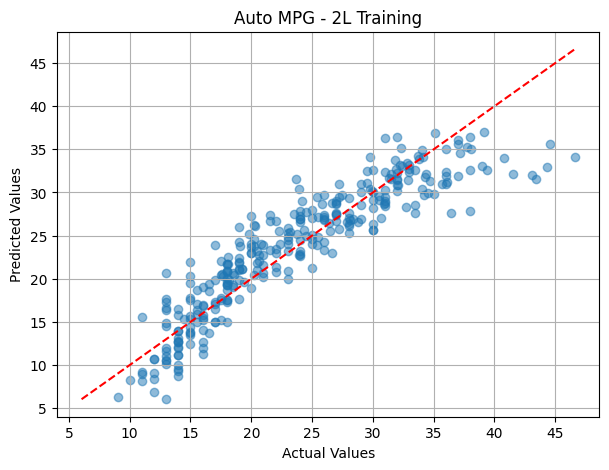

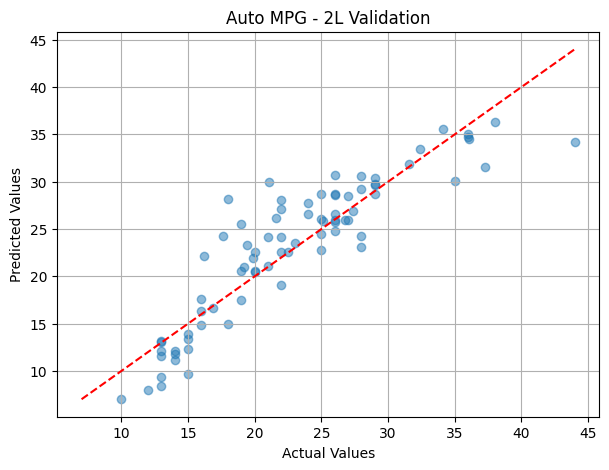

In [273]:
# auto mpg in-sample and validation plots
plot_predictions(model_auto, X_auto_train, y_auto_train, "Auto MPG", "Training")
plot_predictions(model_auto, X_auto_test, y_auto_test, "Auto MPG", "Validation")

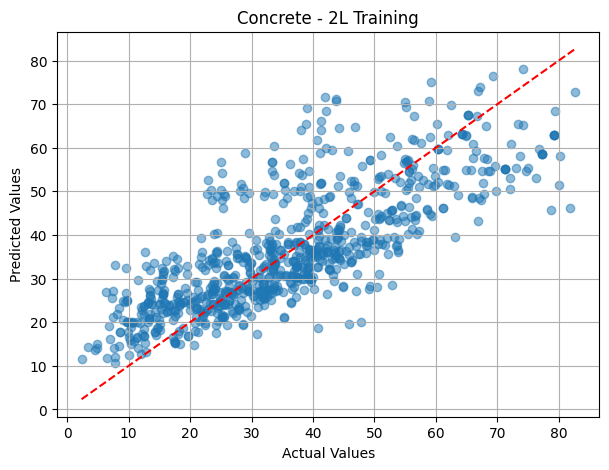

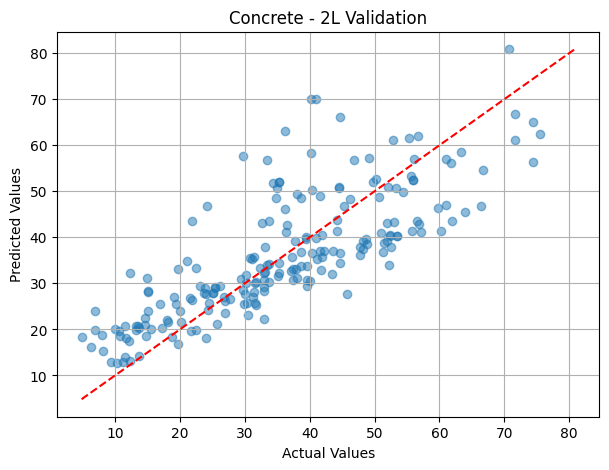

In [274]:
# concrete in-sample and validation plots
plot_predictions(model_concrete, X_concrete_train, y_concrete_train, "Concrete", "Training")
plot_predictions(model_concrete, X_concrete_test, y_concrete_test, "Concrete", "Validation")

In [275]:
# plot residuals for neural network predictions
def plot_residuals(model, X, y, dataset_name, split_name):
    model.eval()

    # generate predictions and get actual values
    torch.set_grad_enabled(False)
    predictions = model(X).numpy().flatten()
    torch.set_grad_enabled(True)
    actual = y.numpy().flatten()

    # calculate residuals
    residuals = actual - predictions

    # plot residuals
    plt.figure(figsize=(7, 5))
    plt.scatter(predictions, residuals, alpha=0.5)
    plt.axhline(y=0, color="red", linestyle="--")

    # plot details
    plt.xlabel("Predicted Values")
    plt.ylabel("Residuals")
    plt.title(f"{dataset_name} - 2L {split_name} Residual Plot")
    plt.grid(True)
    plt.show()

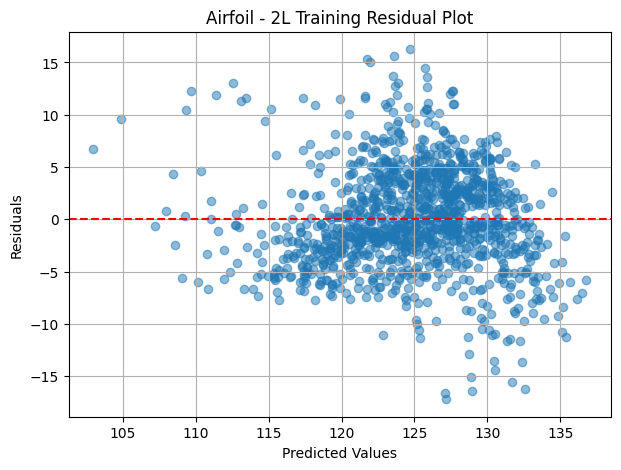

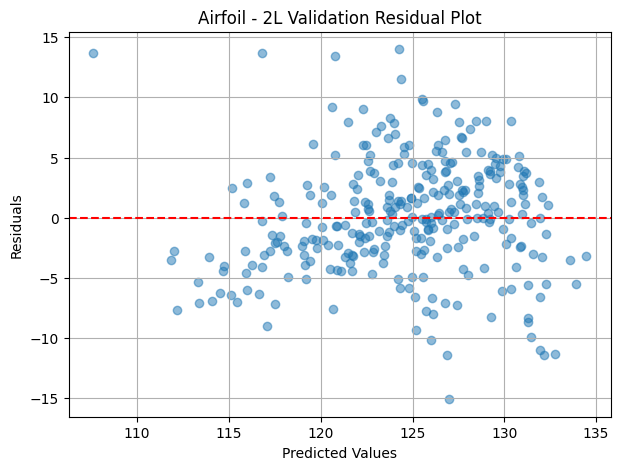

In [276]:
# airfoil in-sample and validation residual plots
plot_residuals(model_airfoil, X_airfoil_train, y_airfoil_train, "Airfoil", "Training")
plot_residuals(model_airfoil, X_airfoil_test, y_airfoil_test, "Airfoil", "Validation")

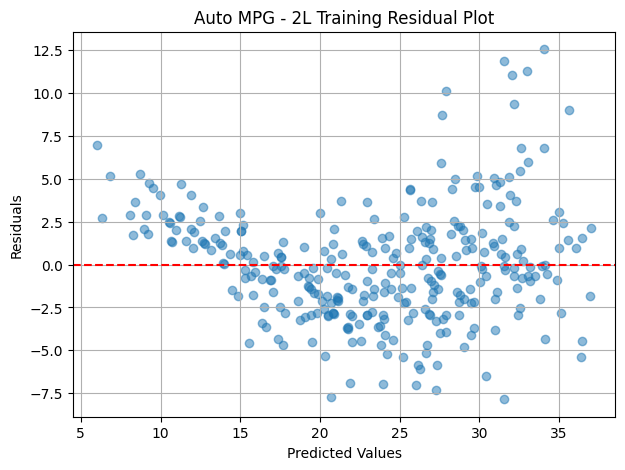

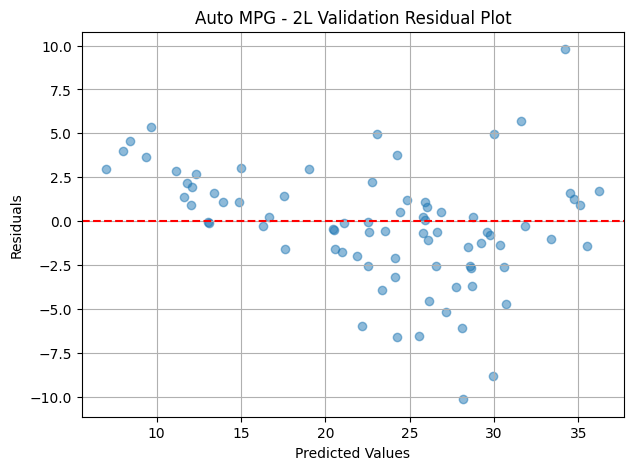

In [277]:
# auto mpg in-sample and validation residual plots
plot_residuals(model_auto, X_auto_train, y_auto_train, "Auto MPG", "Training")
plot_residuals(model_auto, X_auto_test, y_auto_test, "Auto MPG", "Validation")

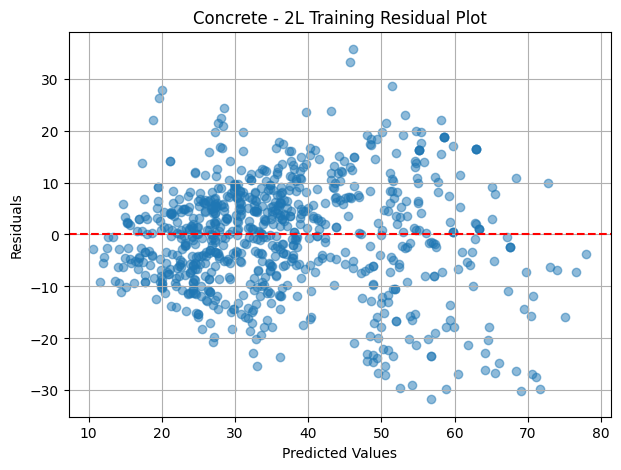

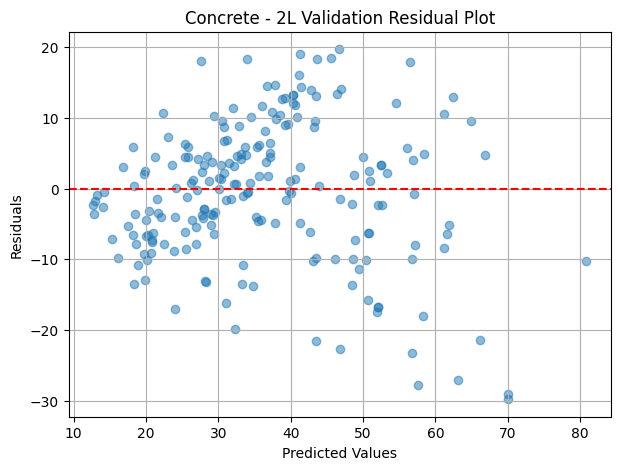

In [278]:
# concrete in-sample and validation residual plots
plot_residuals(model_concrete, X_concrete_train, y_concrete_train, "Concrete", "Training")
plot_residuals(model_concrete, X_concrete_test, y_concrete_test, "Concrete", "Validation")